# China A-Share Fama-French Three-Factor Model

Builds the market (MKT), size (SMB) and value (VMG) factors for China A-shares from monthly data
(Dec 2005 - Feb 2022), then runs per-stock time-series regressions.

The notebook keeps a **first, misaligned version** on purpose: its factor returns use month-*t* returns while the
stock returns being explained are month *t+1*. Section 7 fixes the alignment and shows the effect on R-squared.

In [1]:
import pandas as pd
import numpy as np

In [2]:
import matplotlib.pyplot as plt
import os
os.makedirs('figures', exist_ok=True)
plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.6,
    'axes.prop_cycle': plt.cycler(color=['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#6250d6']),
    'lines.linewidth': 1.8, 'font.size': 10,
})

## 1. Data
Monthly price/valuation panel (`data/Monthly_PB_PS_PE_MV_R_TR.xlsx`, not included - see `data/README.md`). Returns are in percent.

In [3]:
df=pd.read_excel("data/Monthly_PB_PS_PE_MV_R_TR.xlsx")
df.reset_index(inplace=True)
df

,index,stock,number,date,Trading_Volume,return,Turnover_Rate,market_value,PE,PB,PS,next_month_return
0,0,600000.SH,浦发银行,2005-12-30,1.692486e+08,10.6697,18.8054,3.817125e+10,16.4668,2.5770,3.3450,15.5897
1,1,600000.SH,浦发银行,2006-01-25,2.050820e+08,15.5897,22.7869,4.412205e+10,17.7554,2.9788,3.0286,8.1633
2,2,600000.SH,浦发银行,2006-02-28,1.978418e+08,8.1633,21.9824,4.772385e+10,19.2048,3.2219,3.2758,-10.9106
3,3,600000.SH,浦发银行,2006-03-31,1.303215e+08,-10.9106,14.4802,4.251690e+10,16.6211,2.8704,2.9184,0.0000
4,4,600000.SH,浦发银行,2006-04-28,NaN,0.0000,NaN,4.251690e+10,16.6211,2.8704,2.9184,20.9181
...,...,...,...,...,...,...,...,...,...,...,...,...
416836,416836,003816.SZ,中国广核,2021-10-29,2.704618e+09,-13.3531,27.7273,1.474559e+11,14.6166,1.4751,2.0891,-0.6849
416837,416837,003816.SZ,中国广核,2021-11-30,2.039676e+09,-0.6849,20.9104,1.464460e+11,14.5164,1.4650,2.0748,7.9310
416838,416838,003816.SZ,中国广核,2021-12-31,3.340036e+09,7.9310,34.2415,1.580607e+11,15.6677,1.5812,2.2393,-7.9872
416839,416839,003816.SZ,中国广核,2022-01-28,1.582795e+09,-7.9872,16.2265,1.454360e+11,14.4163,1.4549,1.8027,2.0833


In [4]:
df['date'] = df['date'].dt.to_period('M')

In [5]:
# check
last_date=df.groupby('stock')['date'].max()
print('Stocks that exit before the sample ends: '+str((last_date<df['date'].max()).sum())+' / '+str(len(last_date)))
print(df.groupby(df['date'].dt.year)['stock'].nunique())

Stocks that exit before the sample ends: 2 / 3146
date
2005    1266
2006    1332
2007    1449
2008    1513
2009    1580
2010    1804
2011    1959
2012    2041
2013    2057
2014    2130
2015    2266
2016    2415
2017    2712
2018    2788
2019    2869
2020    3012
2021    3133
2022    3144
Name: stock, dtype: int64


## 2. Universe filters
Applied each month:
- drop the bottom 30% by market cap (shell-company risk)
- drop suspended stocks (zero trading volume) and stocks with PB <= 0
- drop stocks listed less than 6 months (except those already listed at the start of the sample)
- require a next-month return

In [6]:
# drop suspended stocks, PB <= 0, stocks listed < 6 months, and rows without next-month return
df['month_num']=df['date'].dt.year*12+df['date'].dt.month
df['list_month']=df.groupby('stock')['month_num'].transform('min')
df['age']=df['month_num']-df['list_month']
df['old_stock']=df['list_month']==df['month_num'].min()
df['threshold'] = df.groupby('date')['market_value'].transform(lambda x: np.nanpercentile(x, 30))
df_new= df[(df['market_value'] > df['threshold'])
           &(df['Trading_Volume']>0)
           &(df['PB']>0)
           &((df['age']>=6)|df['old_stock'])
           &(df['next_month_return'].notna())].copy()
df_new

,index,stock,number,date,Trading_Volume,return,Turnover_Rate,market_value,PE,PB,PS,next_month_return,month_num,list_month,age,old_stock,threshold
0,0,600000.SH,浦发银行,2005-12,1.692486e+08,10.6697,18.8054,3.817125e+10,16.4668,2.5770,3.3450,15.5897,24072,24072,0,True,7.019500e+08
1,1,600000.SH,浦发银行,2006-01,2.050820e+08,15.5897,22.7869,4.412205e+10,17.7554,2.9788,3.0286,8.1633,24073,24072,1,True,7.632392e+08
2,2,600000.SH,浦发银行,2006-02,1.978418e+08,8.1633,21.9824,4.772385e+10,19.2048,3.2219,3.2758,-10.9106,24074,24072,2,True,7.628238e+08
3,3,600000.SH,浦发银行,2006-03,1.303215e+08,-10.9106,14.4802,4.251690e+10,16.6211,2.8704,2.9184,0.0000,24075,24072,3,True,7.449084e+08
5,5,600000.SH,浦发银行,2006-05,6.448170e+08,20.9181,55.1126,3.903255e+10,14.0592,2.4894,2.6793,-0.6018,24077,24072,5,True,9.431803e+08
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
416836,416836,003816.SZ,中国广核,2021-10,2.704618e+09,-13.3531,27.7273,1.474559e+11,14.6166,1.4751,2.0891,-0.6849,24262,24236,26,False,3.640236e+09
416837,416837,003816.SZ,中国广核,2021-11,2.039676e+09,-0.6849,20.9104,1.464460e+11,14.5164,1.4650,2.0748,7.9310,24263,24236,27,False,3.977491e+09
416838,416838,003816.SZ,中国广核,2021-12,3.340036e+09,7.9310,34.2415,1.580607e+11,15.6677,1.5812,2.2393,-7.9872,24264,24236,28,False,4.178450e+09
416839,416839,003816.SZ,中国广核,2022-01,1.582795e+09,-7.9872,16.2265,1.454360e+11,14.4163,1.4549,1.8027,2.0833,24265,24236,29,False,3.860444e+09


In [7]:
df_new['date_new'] = df_new['date'].dt.to_timestamp(how='end')

In [8]:
unique_dates=np.sort(df_new['date_new'].unique())

## 3. 2 x 3 size / book-to-market sorts
Size split at the monthly median (S/B); book-to-market (1/PB) split at the 30th/70th percentiles (G/M/V).

In [9]:
def size_classify(x):
    return pd.qcut(x,[0,0.5,1],labels=['S','B'])
df_new['size']=df_new.groupby('date_new')['market_value'].transform(size_classify)

In [10]:
df_new['BM']=1/df_new['PB']

In [11]:
def BM_classify(x):
    return pd.qcut(x, [0, 0.3, 0.7, 1.0], labels=['G', 'M', 'V'])
df_new['BM_group'] = df_new.groupby('date_new')['BM'].transform(BM_classify)

In [12]:
df_new.groupby('BM_group', observed=False)['BM'].mean()

BM_group
G    0.173120
M    0.380391
V    0.758453
Name: BM, dtype: float64

In [13]:
df_new.groupby('size', observed=False)['market_value'].mean()

size
S    5.259881e+09
B    4.313723e+10
Name: market_value, dtype: float64

In [14]:
SV=df_new[(df_new['size']=='S')&(df_new['BM_group']=='V')]
SM=df_new[(df_new['size']=='S')&(df_new['BM_group']=='M')]
SG=df_new[(df_new['size']=='S')&(df_new['BM_group']=='G')]
BV=df_new[(df_new['size']=='B')&(df_new['BM_group']=='V')]
BM=df_new[(df_new['size']=='B')&(df_new['BM_group']=='M')]
BG=df_new[(df_new['size']=='B')&(df_new['BM_group']=='G')]

## 4. Factor construction - first pass (misaligned)
Value-weighted returns of the six portfolios, SMB and VMG.
**Note:** this pass uses `return` (month *t*), i.e. the same month in which the portfolios are formed. It is kept to
demonstrate the timing error; the corrected construction is in Section 7.

In [15]:
groups = {'SV': SV, 'SM': SM, 'SG': SG,'BV': BV, 'BM': BM, 'BG': BG}
portfolio_returns={name:i.groupby('date_new')[['return','market_value']].apply(lambda x: (x['return']*x['market_value']).sum()/x['market_value'].sum()) for name,i in groups.items()}
pr_df=pd.DataFrame(portfolio_returns)
pr_df

,SV,SM,SG,BV,BM,BG
date_new,,,,,,
2005-12-31 23:59:59.999999,2.270524,2.107737,1.443822,5.025749,8.913090,7.441339
2006-01-31 23:59:59.999999,9.467324,9.444424,11.312510,7.990636,8.762757,14.219389
2006-02-28 23:59:59.999999,3.304567,1.086694,2.202244,3.529164,4.598954,5.375557
2006-03-31 23:59:59.999999,-0.254593,1.329296,3.366290,-1.993129,-0.249257,6.407447
2006-04-30 23:59:59.999999,5.318024,11.882690,16.410546,3.430368,13.935245,28.299843
...,...,...,...,...,...,...
2021-10-31 23:59:59.999999,-5.855671,-2.266904,4.973968,-3.444854,-1.431555,5.790060
2021-11-30 23:59:59.999999,2.829493,12.925750,17.738922,-2.777691,1.413710,3.365829
2021-12-31 23:59:59.999999,6.855123,4.256896,7.845673,4.057400,5.010972,1.702051


In [16]:
SMB=pd.DataFrame((pr_df['SV']+pr_df['SM']+pr_df['SG']-pr_df['BG']-pr_df['BV']-pr_df['BM'])/3,unique_dates,columns=['SMB_monthly'])
print(SMB.head())

                            SMB_monthly
2005-12-31 23:59:59.999999    -5.186031
2006-01-31 23:59:59.999999    -0.249508
2006-02-28 23:59:59.999999    -2.303390
2006-03-31 23:59:59.999999     0.091977
2006-04-30 23:59:59.999999    -4.018065


In [17]:
VMG=pd.DataFrame((pr_df['SV']+pr_df['BV']-pr_df['SG']-pr_df['BG'])/2,unique_dates,columns=['VMG_monthly'])
print(VMG.head())

                            VMG_monthly
2005-12-31 23:59:59.999999    -0.794444
2006-01-31 23:59:59.999999    -4.036969
2006-02-28 23:59:59.999999    -0.372035
2006-03-31 23:59:59.999999    -6.010729
2006-04-30 23:59:59.999999   -17.980999


In [18]:
df_new['weighted_ret'] = df_new['return'] * df_new['market_value']
MKT_series = df_new.groupby('date_new')[['weighted_ret','market_value']].apply(lambda x: x['weighted_ret'].sum() / x['market_value'].sum()).rename("Rm")
Rm=pd.DataFrame(MKT_series)
print(Rm.head())

                                   Rm
date_new                             
2005-12-31 23:59:59.999999   6.871398
2006-01-31 23:59:59.999999  10.468005
2006-02-28 23:59:59.999999   4.450346
2006-03-31 23:59:59.999999   1.881355
2006-04-30 23:59:59.999999  16.128015


## 5. Risk-free rate
One-year deposit rate (`data/Rf_data.xlsx`), matched to each month with an as-of merge and converted to a monthly rate.

In [19]:
df_rate=pd.read_excel("data/Rf_data.xlsx")
df_rate['adjusted_date'] = pd.to_datetime(df_rate['adjusted_date']).astype('datetime64[ns]')
df_new['date_new'] = pd.to_datetime(df_new['date_new']).astype('datetime64[ns]')
df_rate = df_rate.sort_values('adjusted_date')
df_new = df_new.sort_values('date_new')
df_final = pd.merge_asof(df_new, df_rate, left_on='date_new', right_on='adjusted_date', direction='backward')
print(df_final.head())

    index      stock number     date  Trading_Volume   return  Turnover_Rate  \
0       0  600000.SH   浦发银行  2005-12     169248599.0  10.6697        18.8054   
1  284783  000933.SZ   神火股份  2005-12      37648227.0  11.2878        20.6858   
2  207733  000001.SZ   平安银行  2005-12     151640991.0   5.1370        10.7595   
3   59770  600377.SH   宁沪高速  2005-12      15199685.0   5.1071        10.1331   
4  233617  000548.SZ   湖南投资  2005-12      20527188.0   4.4248        11.6479   

   market_value       PE      PB  ...  age  old_stock     threshold  \
0  3.817125e+10  16.4668  2.5770  ...    0       True  7.019500e+08   
1  3.500000e+09   7.4665  2.4330  ...    0       True  7.019500e+08   
2  1.194735e+10  47.9506  2.3823  ...    0       True  7.019500e+08   
3  3.214083e+10  58.0031  2.2276  ...    0       True  7.019500e+08   
4  8.038350e+08 -40.7645  0.7230  ...    0       True  7.019500e+08   

                    date_new  size        BM  BM_group  weighted_ret  \
0 2005-12-31 23:59:5

In [20]:
Rf_monthly=df_final.groupby('date_new')['Rf'].mean()/12
MKT = pd.DataFrame(MKT_series - Rf_monthly, columns=['MKT_monthly'])

## 6. Time-series regressions - misaligned version
Excess next-month stock returns regressed on the first-pass factors: one example stock, then every stock with at least 36 months of data.

In [21]:
test_stock_code='600000.SH'
test_stock=df_final[(df_final['stock']==test_stock_code)]
test_stock

,index,stock,number,date,Trading_Volume,return,Turnover_Rate,market_value,PE,PB,...,age,old_stock,threshold,date_new,size,BM,BM_group,weighted_ret,adjusted_date,Rf
0,0,600000.SH,浦发银行,2005-12,169248599.0,10.6697,18.8054,3.817125e+10,16.4668,2.5770,...,0,True,7.019500e+08,2005-12-31 23:59:59.999999,B,0.388048,G,4.072758e+11,2004-10-29,2.25
1228,1,600000.SH,浦发银行,2006-01,205081972.0,15.5897,22.7869,4.412205e+10,17.7554,2.9788,...,1,True,7.632392e+08,2006-01-31 23:59:59.999999,B,0.335706,G,6.878495e+11,2004-10-29,2.25
2472,2,600000.SH,浦发银行,2006-02,197841835.0,8.1633,21.9824,4.772385e+10,19.2048,3.2219,...,2,True,7.628238e+08,2006-02-28 23:59:59.999999,B,0.310376,G,3.895841e+11,2004-10-29,2.25
3442,3,600000.SH,浦发银行,2006-03,130321528.0,-10.9106,14.4802,4.251690e+10,16.6211,2.8704,...,3,True,7.449084e+08,2006-03-31 23:59:59.999999,B,0.348384,G,-4.638849e+11,2004-10-29,2.25
4582,5,600000.SH,浦发银行,2006-05,644817023.0,20.9181,55.1126,3.903255e+10,14.0592,2.4894,...,5,True,9.431803e+08,2006-05-31 23:59:59.999999,B,0.401703,M,8.164868e+11,2006-04-28,2.25
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
267807,190,600000.SH,浦发银行,2021-10,514604947.0,-0.6667,1.7532,2.624084e+11,4.4320,0.4860,...,190,True,3.640236e+09,2021-10-31 23:59:59.999999,B,2.057613,V,-1.749477e+11,2015-10-24,1.50
269139,191,600000.SH,浦发银行,2021-11,599859239.0,-4.8098,2.0437,2.497869e+11,4.5318,0.4543,...,191,True,3.977491e+09,2021-11-30 23:59:59.999999,B,2.201189,V,-1.201425e+12,2015-10-24,1.50
270953,192,600000.SH,浦发银行,2021-12,671213535.0,0.2350,2.2868,2.503740e+11,4.5424,0.4554,...,192,True,4.178450e+09,2021-12-31 23:59:59.999999,B,2.195872,V,5.883789e+10,2015-10-24,1.50
273103,193,600000.SH,浦发银行,2022-01,833546878.0,-1.4068,2.8398,2.468517e+11,4.4785,0.4490,...,193,True,3.860444e+09,2022-01-31 23:59:59.999999,B,2.227171,V,-3.472710e+11,2015-10-24,1.50


In [22]:
y=test_stock[['date_new','next_month_return']].set_index('date_new')
y.dropna(inplace=True)
y['next_month_return']=y['next_month_return']-Rf_monthly.loc[y.index]
y

,next_month_return
date_new,
2005-12-31 23:59:59.999999,15.4022
2006-01-31 23:59:59.999999,7.9758
2006-02-28 23:59:59.999999,-11.0981
2006-03-31 23:59:59.999999,-0.1875
2006-05-31 23:59:59.999999,-0.7893
...,...
2021-10-31 23:59:59.999999,-4.9348
2021-11-30 23:59:59.999999,0.1100
2021-12-31 23:59:59.999999,-1.5318


In [23]:
X=pd.concat([MKT,SMB,VMG],axis=1)
X.dropna(inplace=True)
X

,MKT_monthly,SMB_monthly,VMG_monthly
2005-12-31 23:59:59.999999,6.683898,-5.186031,-0.794444
2006-01-31 23:59:59.999999,10.280505,-0.249508,-4.036969
2006-02-28 23:59:59.999999,4.262846,-2.303390,-0.372035
2006-03-31 23:59:59.999999,1.693855,0.091977,-6.010729
2006-04-30 23:59:59.999999,15.940515,-4.018065,-17.980999
...,...,...,...
2021-10-31 23:59:59.999999,0.628648,-1.354086,-10.032276
2021-11-30 23:59:59.999999,1.688069,10.497439,-10.526475
2021-12-31 23:59:59.999999,3.475737,2.729090,0.682399
2022-01-31 23:59:59.999999,-6.878288,-2.221672,6.739685


In [24]:
import statsmodels.api as sm
from statsmodels import regression
X_test=sm.add_constant(X.loc[y.index])
model=regression.linear_model.OLS(y,X_test).fit()
alpha=model.params.iloc[0]
beta1=model.params.iloc[1]
beta2=model.params.iloc[2]
beta3=model.params.iloc[3]
print('alpha:'+str(alpha))
print('beta1:'+str(beta1))
print('beta2:'+str(beta2))
print('beta3:'+str(beta3))
print(model.summary())

alpha:0.9157094546520398
beta1:0.13603581576962054
beta2:0.007718871801068451
beta3:-0.014870859793363316
                            OLS Regression Results                            
Dep. Variable:      next_month_return   R-squared:                       0.011
Model:                            OLS   Adj. R-squared:                 -0.004
Method:                 Least Squares   F-statistic:                    0.7350
Date:                Wed, 21 Oct 2026   Prob (F-statistic):              0.532
Time:                        18:08:21   Log-Likelihood:                -726.60
No. Observations:                 194   AIC:                             1461.
Df Residuals:                     190   BIC:                             1474.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
------------------------

In [25]:
min_obs=36
test_stock_list=df_new['stock'].unique()
R2=[]
for stock in test_stock_list:
    y=df_new[df_new['stock']==stock][['date_new','next_month_return']].set_index('date_new')
    y.dropna(inplace=True)
    if len(y)<min_obs:
        continue
    y['next_month_return']=y['next_month_return']-Rf_monthly.loc[y.index]
    X_stock = X.reindex(y.index)
    mask = X_stock.notna().all(axis=1)
    X_stock = X_stock[mask]
    y = y[mask]
    X_stock=sm.add_constant(X_stock)
    model=regression.linear_model.OLS(y,X_stock).fit()
    R2.append(model.rsquared)

In [26]:
R2_df=pd.DataFrame(R2)
R2_df.dropna(inplace=True)
print(R2_df.describe())

                 0
count  2186.000000
mean      0.034199
std       0.032677
min       0.000180
25%       0.012516
50%       0.023953
75%       0.044908
max       0.340876


## 7. Fix: align factor returns with next-month stock returns
Portfolios are still formed on month-*t* characteristics, but factor returns now use `next_month_return`, so factors
and stock returns cover the same month. Regressions use HAC (Newey-West, 3 lags) standard errors.

In [27]:
# value-weighted
portfolio_returns_v2 = {name: i.groupby('date_new')[['next_month_return','market_value']].apply(lambda x: (x['next_month_return']*x['market_value']).sum()/x['market_value'].sum()) for name, i in groups.items()}
pr_df_v2 = pd.DataFrame(portfolio_returns_v2)

# SMB / VMG
SMB_v2 = pd.DataFrame((pr_df_v2['SV']+pr_df_v2['SM']+pr_df_v2['SG']-pr_df_v2['BG']-pr_df_v2['BV']-pr_df_v2['BM'])/3, unique_dates, columns=['SMB_monthly'])
VMG_v2 = pd.DataFrame((pr_df_v2['SV']+pr_df_v2['BV']-pr_df_v2['SG']-pr_df_v2['BG'])/2,
                      unique_dates, columns=['VMG_monthly'])

# MKT
df_new['weighted_ret_v2'] = df_new['next_month_return'] * df_new['market_value']
MKT_series_v2 = df_new.groupby('date_new')[['weighted_ret_v2','market_value']].apply(lambda x: x['weighted_ret_v2'].sum() / x['market_value'].sum()).rename("Rm_v2")
MKT_v2 = pd.DataFrame(MKT_series_v2 - Rf_monthly, columns=['MKT_monthly'])

In [28]:
X_v2 = pd.concat([MKT_v2, SMB_v2, VMG_v2], axis=1)
X_v2.dropna(inplace=True)

y = test_stock[['date_new','next_month_return']].set_index('date_new')
y.dropna(inplace=True)
y['next_month_return']=y['next_month_return']-Rf_monthly.loc[y.index]

X_v2s = sm.add_constant(X_v2.loc[y.index.unique()])
model_v2 = regression.linear_model.OLS(y, X_v2s).fit(cov_type='HAC', cov_kwds={'maxlags':3})
print(model_v2.summary())

                            OLS Regression Results                            
Dep. Variable:      next_month_return   R-squared:                       0.587
Model:                            OLS   Adj. R-squared:                  0.580
Method:                 Least Squares   F-statistic:                     59.57
Date:                Wed, 21 Oct 2026   Prob (F-statistic):           3.43e-27
Time:                        18:09:20   Log-Likelihood:                -642.01
No. Observations:                 194   AIC:                             1292.
Df Residuals:                     190   BIC:                             1305.
Df Model:                           3                                         
Covariance Type:                  HAC                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const           0.4246      0.496      0.856      

In [29]:
R2_v2 = []
for stock in test_stock_list:
    yy = df_new[df_new['stock']==stock][['date_new','next_month_return']].set_index('date_new')
    yy.dropna(inplace=True)
    if len(yy)<min_obs:
        continue
    yy['next_month_return']=yy['next_month_return']-Rf_monthly.loc[yy.index]
    Xs = X_v2.reindex(yy.index)
    mask = Xs.notna().all(axis=1)
    Xs, yy = Xs[mask], yy[mask]
    Xs = sm.add_constant(Xs)
    R2_v2.append(regression.linear_model.OLS(yy, Xs).fit().rsquared)
R2_v2_df = pd.DataFrame(R2_v2).replace([np.inf, -np.inf], np.nan).dropna()
print(R2_v2_df.describe())

                 0
count  2186.000000
mean      0.436356
std       0.132427
min       0.041365
25%       0.350716
50%       0.443361
75%       0.532041
max       0.789820


## 8. Summary

In [30]:
print("\n[Factor Returns & Significance]")
print(f"  {'Factor':<12} | {'Monthly':>8} | {'Annualized':>11} | {'t-stat (HAC)':>12}")
print("  " + "-" * 50)
for name in ['MKT_monthly', 'SMB_monthly', 'VMG_monthly']:
    # OLS, lags:3
    m = regression.linear_model.OLS(X_v2[name], np.ones(len(X_v2))).fit(cov_type='HAC', cov_kwds={'maxlags':3})
    monthly = X_v2[name].mean()
    annual = monthly * 12
    t_stat = m.tvalues.iloc[0]
    print(f"  {name:<12} | {monthly:>7.3f}% | {annual:>10.2f}% | {t_stat:>12.2f}")
print("\n[Regression Fit & Sample Stats]")
print(f"  Median R2: {R2_df[0].median():.3f} (misaligned) -> {R2_v2_df[0].median():.3f} (aligned)")
print(f"  Stocks regressed: {len(R2_v2_df)} (min {min_obs} months)")
avg_stocks = df_new.groupby('date_new').size().mean()
print(f"  Avg stocks per month: {avg_stocks:.0f}")


[Factor Returns & Significance]
  Factor       |  Monthly |  Annualized | t-stat (HAC)
  --------------------------------------------------
  MKT_monthly  |   0.924% |      11.09% |         1.42
  SMB_monthly  |   0.572% |       6.86% |         1.44
  VMG_monthly  |   0.679% |       8.14% |         2.07

[Regression Fit & Sample Stats]
  Median R2: 0.024 (misaligned) -> 0.443 (aligned)
  Stocks regressed: 2186 (min 36 months)
  Avg stocks per month: 1422


## 9. Figures

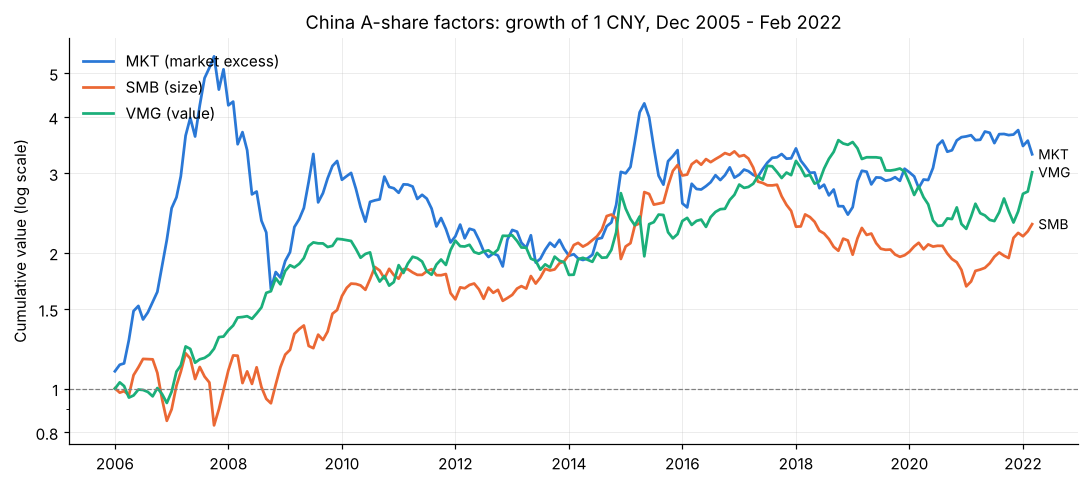

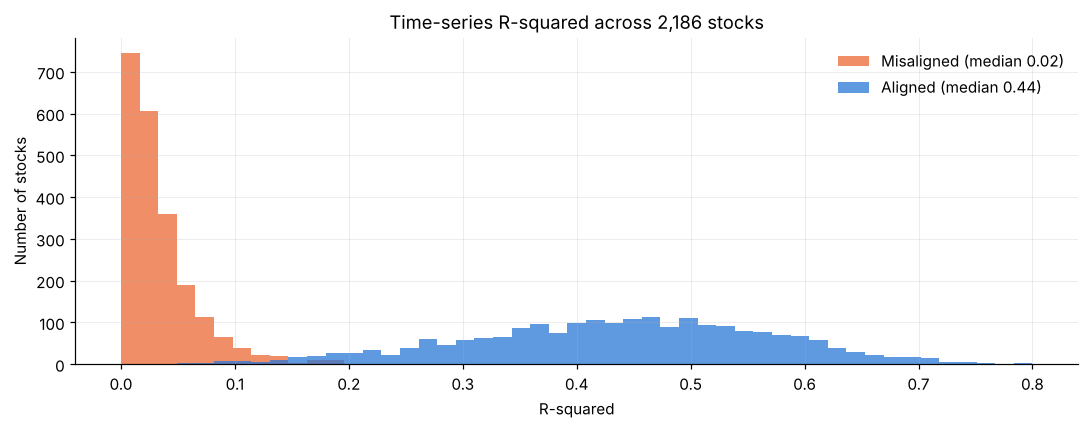

In [31]:
# Cumulative long-short factor returns (aligned version)
cum = (1 + X_v2 / 100).cumprod()
fig, ax = plt.subplots(figsize=(10, 4.5))
labels = {'MKT_monthly': 'MKT (market excess)', 'SMB_monthly': 'SMB (size)', 'VMG_monthly': 'VMG (value)'}
for col in cum.columns:
    ax.plot(cum.index, cum[col], label=labels[col])
    ax.annotate(labels[col].split(' ')[0], (cum.index[-1], cum[col].iloc[-1]), xytext=(4, 0),
                textcoords='offset points', va='center', fontsize=9)
ax.axhline(1, color='grey', lw=0.8, ls='--')
ax.set_yscale('log')
from matplotlib.ticker import FuncFormatter, NullFormatter
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}')); ax.yaxis.set_minor_formatter(NullFormatter())
ax.set_yticks([0.8, 1, 1.5, 2, 3, 4, 5])
ax.set_title('China A-share factors: growth of 1 CNY, Dec 2005 - Feb 2022')
ax.set_ylabel('Cumulative value (log scale)')
ax.legend(loc='upper left', frameon=False)
plt.tight_layout(); plt.savefig('figures/cumulative_factor_returns.png', dpi=150, bbox_inches='tight'); plt.show()

# Distribution of per-stock R-squared: misaligned vs aligned
fig, ax = plt.subplots(figsize=(10, 4))
bins = np.linspace(0, 0.8, 50)
ax.hist(R2_df[0], bins=bins, alpha=0.75, label=f'Misaligned (median {R2_df[0].median():.2f})', color='#eb6834')
ax.hist(R2_v2_df[0], bins=bins, alpha=0.75, label=f'Aligned (median {R2_v2_df[0].median():.2f})', color='#2a78d6')
ax.set_title(f'Time-series R-squared across {len(R2_v2_df):,} stocks')
ax.set_xlabel('R-squared'); ax.set_ylabel('Number of stocks')
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig('figures/r2_distribution.png', dpi=150, bbox_inches='tight'); plt.show()